# Does sector diversification survive market crises?

An equal-weight portfolio of the nine original S&P 500 sector ETFs spreads its risk across the whole economy. This notebook asks whether that diversification still works when the market falls: how sector correlations and volatilities change in crises, how much of the change is a volatility effect, whether stress-test correlation matrices remain usable, and what it all means for portfolio losses.

**Key findings**

- **It depends on the type of crisis.** The average pairwise correlation between sectors is 0.59 in calm periods. It *fell* to 0.44 during the 2000–2002 dot-com bust, a sector rotation in which technology crashed while defensive sectors held, but rose to 0.73 in 2007–2009 and 0.88 in the 2020 Covid crash.
- **Volatility, not correlation, drives crisis losses.** In a Gaussian Monte Carlo with the same expected returns everywhere, moving from calm to 2007–2009 conditions raises the probability of losing more than 20% over one year from 1.8% to 22.1%. Averaged over both orders of the decomposition, crisis volatilities account for 18.7 percentage points of that rise and crisis correlations for 1.6.
- **Sector diversification was weak to begin with.** In calm markets, the diversification ratio (average sector volatility divided by portfolio volatility) is only 1.25: even if every correlation rose to 1, portfolio volatility could increase by at most 25%, from 15.0% to 18.8%. Crisis volatilities, by contrast, more than double sector volatility (18.8% to 41.1%). There was little to lose because there was little to gain. Under a worst-case stress matrix, the ratio falls to 1.05: nine sectors then behave almost like one.
- **Most of the correlation spike is a volatility effect.** After the Forbes & Rigobon (2002) correction, crisis correlations fall to 0.32–0.48, below the calm level, consistent with "no contagion, only interdependence". The correction probably overshoots, and investors bear the raw correlations anyway.
- **A common stress-testing shortcut breaks Cholesky.** Taking, for each pair, the highest correlation seen in any crisis gives a matrix that is not positive definite (smallest eigenvalue −0.045). Higham's (2002) nearest correlation matrix repairs it with a largest change of 0.015.
- **One factor dominates in crises.** The first eigenvalue of the correlation matrix explains 64% of sector variance in calm periods and 90% during the 2020 crash.

**Data**

| | |
|:---|:---|
| Assets | Nine SPDR sector ETFs (XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV, XLY) and SPY as market benchmark — Yahoo Finance via `yfinance`, adjusted closes (dividends reinvested) |
| Excluded | XLRE (real estate, launched 2015) and XLC (communication services, launched 2018): too recent |
| Period | 4 January 1999 to 30 September 2026: 6,978 common trading days, 6,977 daily returns |
| Returns | Daily log returns for covariances, correlations and eigenvalues; daily simple returns for drawdowns and the Monte Carlo |
| Crises | SPY total-return drawdowns of at least 20%, from peak to trough, detected from the data |
| Portfolio | Equal weights across the nine sectors, rebalanced daily |

**Method**

| Section | Content |
|:---|:---|
| 1. Data | Download, common trading days, sanity checks |
| 2. Crisis detection | Peak-to-trough SPY drawdowns of at least 20% |
| 3. Covariance and correlation | Calm vs crisis matrices, conversion Σ = DRD, positive (semi-)definiteness |
| 4. Volatility correction | Forbes & Rigobon (2002) adjustment of crisis correlations |
| 5. Absorption ratio | Eigenvalue decomposition by regime and on rolling windows (Kritzman et al., 2011) |
| 6. Stress matrices | A non-positive-definite stress matrix, repaired by eigenvalue clipping and by Higham (2002) |
| 7. Monte Carlo | Cholesky simulation of the portfolio under five scenarios, with a decomposition of the crisis effect |
| 8. Conclusion | Answer, limitations and references |

Section 7 uses **simulated** returns; every simulated figure is labelled as such.

In [1]:
# --- setup ---
import os

import numpy as np
import pandas as pd
import yfinance as yf

import matplotlib.pyplot as plt

os.makedirs("assets", exist_ok=True)   # output folder for the README figures

# --- parameters ---
TICKERS = {
    "XLB": "Materials", "XLE": "Energy", "XLF": "Financials",
    "XLI": "Industrials", "XLK": "Technology", "XLP": "Consumer Staples",
    "XLU": "Utilities", "XLV": "Health Care", "XLY": "Consumer Discretionary",
    "SPY": "S&P 500",
}
SECTORS = [name for t, name in TICKERS.items() if t != "SPY"]
BENCHMARK = "S&P 500"
START = "1999-01-01"
END = "2026-10-01"          # fixed end date: results are reproducible
TRADING_DAYS = 252
CRISIS_THRESHOLD = -0.20      # bear market: at least -20% from the last peak

N_FACTORS = 2                  # about 1/5 of the 9 sectors (Kritzman et al., 2011)
AR_WINDOWS = (500, 63)         # Kritzman's 500 days, and one quarter

EIG_FLOOR = 1e-8   # Cholesky needs STRICTLY positive eigenvalues: floor at 1e-8, not 0
EXPERT_OVERRIDES = {("Technology", "Energy"): 0.95,          # "tech will crash with oil"
                    ("Technology", "Consumer Staples"): 0.95,  # "...and with staples"
                    ("Energy", "Consumer Staples"): 0.00}      # "...but oil and staples are unrelated"

N_PATHS = 10_000
HORIZONS = {"1 day": 1, "1 month": 21, "1 year": 252}
LOSS_LEVELS = (0.10, 0.20)
REF_CRISIS = "2007–2009"          # systemic crisis with enough days for a stable estimate
SEED = 42
WEIGHTS = np.full(len(SECTORS), 1 / len(SECTORS))   # equal weights, rebalanced daily


## 1. Data

Adjusted closes of the nine sector ETFs and SPY are downloaded together, and only the days on which all ten series trade are kept, before returns are computed. A ticker that fails to download raises an explicit error instead of silently returning an empty column.

In [2]:
def get_returns(tickers, start, end):
    """Download adjusted closes, keep common trading days, return simple and log returns."""
    try:
        prices = yf.download(list(tickers), start=start, end=end,
                             auto_adjust=True, progress=False)["Close"]
    except Exception as e:
        raise RuntimeError(f"Download failed for {list(tickers)}: {e}") from e

    # a failed ticker comes back as an all-NaN column (yfinance does not raise)
    missing = [t for t in tickers if t not in prices or prices[t].isna().all()]
    if missing:
        raise ValueError(f"No data for: {missing}")

    prices = prices[list(tickers)].rename(columns=tickers).dropna()  # common days BEFORE returns
    prices.columns.name = None   # remove the "Ticker" label left by yfinance

    returns = pd.concat({"simple": prices.pct_change(),
                         "log": np.log(prices).diff()}, axis=1).dropna()

    print(f"{len(returns)} common return days | {returns.index[0].date()} to {returns.index[-1].date()}")
    return returns


def data_checks(returns, benchmark=BENCHMARK, periods=TRADING_DAYS, n_worst=5):
    """Missing values, worst benchmark days and annualized volatility of each series."""
    log_r = returns["log"]
    print(f"Missing values: {int(returns.isna().sum().sum())}")

    worst = returns["simple"][benchmark].nsmallest(n_worst)
    print(f"\n{n_worst} worst days of the {benchmark} (simple returns):")
    print(worst.map("{:.2%}".format).to_string())

    vol = (log_r.std() * np.sqrt(periods)).sort_values()
    print("\nAnnualized volatility (log returns):")
    print(vol.map("{:.1%}".format).to_string())
    return vol

In [3]:
# --- run ---
returns = get_returns(TICKERS, START, END)
vol = data_checks(returns)

6977 common return days | 1999-01-05 to 2026-09-30
Missing values: 0

5 worst days of the S&P 500 (simple returns):
Date
2020-03-16    -10.94%
2008-10-15     -9.84%
2020-03-12     -9.57%
2008-12-01     -8.86%
2008-09-29     -7.84%

Annualized volatility (log returns):
Consumer Staples          15.2%
Health Care               17.8%
Utilities                 19.2%
S&P 500                   19.2%
Industrials               21.1%
Consumer Discretionary    22.7%
Materials                 23.5%
Technology                26.0%
Financials                28.2%
Energy                    28.7%


The sample covers 6,977 daily returns (6,978 common trading days, from 4 January 1999 to 30 September 2026), with no missing values. The five worst days of the SPY are the expected ones: March 2020 and the autumn of 2008. Volatilities range from 15.2% (Consumer Staples) to 28.7% (Energy). The S&P 500 itself (19.2%) is less volatile than seven of the nine sectors: mixing sectors already offsets part of their moves. The question is whether this still holds in crises.

## 2. Crisis detection

Crises are not chosen by hand. They are detected with a rule fixed in advance: a fall of at least 20% in the SPY total-return index from its previous peak (the usual definition of a bear market). Each crisis runs from the peak to the trough. An episode starts at a new high and lasts until the next one; the crisis window contains the return days of the decline, (peak, trough]. All other days are treated as calm.

In [4]:
def benchmark_drawdown(returns, benchmark=BENCHMARK):
    """Drawdown of the benchmark total-return index (adjusted prices, dividends included)."""
    wealth = (1 + returns["simple"][benchmark]).cumprod()
    return wealth / wealth.cummax() - 1


def find_crises(drawdown, threshold=CRISIS_THRESHOLD):
    """Peak-to-trough episodes whose maximum drawdown is at or below `threshold`.

    An episode starts at a new high (drawdown = 0) and lasts until the next new high.
    The crisis window is (peak, trough]: the return days of the decline itself.
    """
    episode = (drawdown == 0).cumsum()          # new id at every new high
    rows = []
    for _, dd in drawdown.groupby(episode):
        if dd.min() > threshold:
            continue
        peak, trough = dd.index[0], dd.idxmin()
        n_days = len(dd.loc[peak:trough]) - 1   # return days after the peak
        label = f"{peak.year}" if peak.year == trough.year else f"{peak.year}–{trough.year}"
        rows.append({"Crisis": label, "Peak": peak.date(), "Trough": trough.date(),
                     "Max drawdown": dd.min(), "Trading days": n_days})
    return pd.DataFrame(rows).set_index("Crisis")


def crisis_mask(index, crises):
    """Boolean Series: True on the return days of any crisis window (peak, trough]."""
    mask = pd.Series(False, index=index)
    for peak, trough in zip(crises["Peak"], crises["Trough"]):
        mask |= (index > pd.Timestamp(peak)) & (index <= pd.Timestamp(trough))
    return mask


def plot_drawdown(drawdown, crises, threshold=CRISIS_THRESHOLD, benchmark=BENCHMARK):
    """Benchmark drawdown with the crisis windows shaded."""
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.fill_between(drawdown.index, drawdown, 0, color="grey", alpha=0.4, linewidth=0)
    ax.plot(drawdown.index, drawdown, color="black", linewidth=0.8)
    ax.axhline(threshold, color="red", linestyle="--", linewidth=1,
               label=f"Crisis threshold ({threshold:.0%})")
    for name, row in crises.iterrows():
        ax.axvspan(pd.Timestamp(row["Peak"]), pd.Timestamp(row["Trough"]),
                   color="red", alpha=0.12)
        ax.text(pd.Timestamp(row["Peak"]), 0.02, name, fontsize=9, va="bottom")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylim(drawdown.min() * 1.1, 0.12)
    ax.set_ylabel("Drawdown from previous peak")
    ax.set_title(f"{benchmark} drawdown (total return) and crisis windows, peak to trough")
    ax.legend(loc="lower left", frameon=False)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax

,Peak,Trough,Max drawdown,Trading days
Crisis,,,,
2000–2002,2000-03-24,2002-10-09,-47.5%,637
2007–2009,2007-10-09,2009-03-09,-55.2%,355
2020,2020-02-19,2020-03-23,-33.7%,23
2022,2022-01-03,2022-10-12,-24.5%,195


Crisis days: 1210 | Calm days: 5767 | Total: 6977


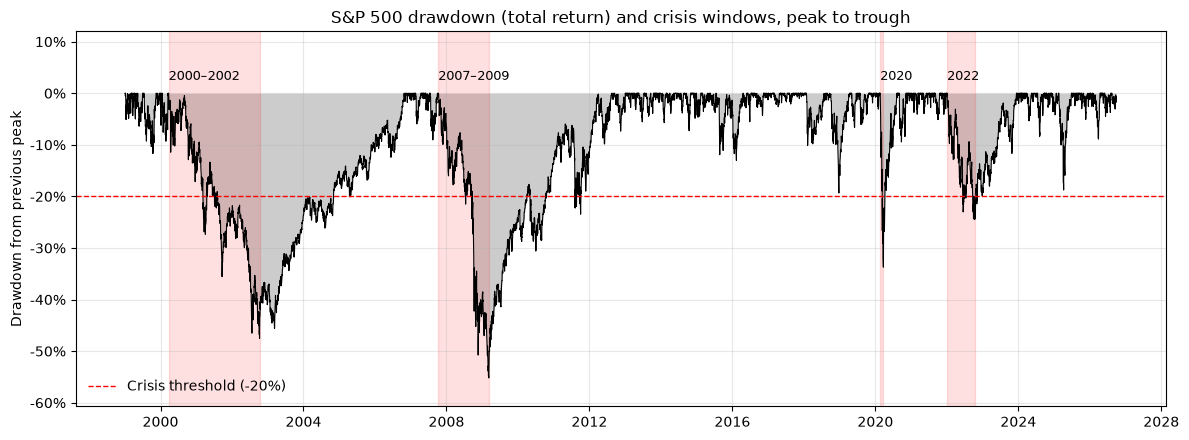

In [5]:
# --- run ---
drawdown = benchmark_drawdown(returns)
crises = find_crises(drawdown)
in_crisis = crisis_mask(returns.index, crises)

display(crises.style.format({"Max drawdown": "{:.1%}"}))
print(f"Crisis days: {in_crisis.sum()} | Calm days: {(~in_crisis).sum()} | Total: {len(in_crisis)}")

fig, ax = plot_drawdown(drawdown, crises)
fig.savefig("assets/spy_drawdown_crises.png", dpi=150, bbox_inches="tight")
plt.show()

Four crises are detected:

| Crisis | Peak | Trough | Max drawdown | Trading days |
|:---|:---|:---|:---|:---|
| 2000–2002 | 2000-03-24 | 2002-10-09 | −47.5% | 637 |
| 2007–2009 | 2007-10-09 | 2009-03-09 | −55.2% | 355 |
| 2020 | 2020-02-19 | 2020-03-23 | −33.7% | 23 |
| 2022 | 2022-01-03 | 2022-10-12 | −24.5% | 195 |

That is 1,210 crisis days and 5,767 calm days (days are counted in daily returns). Three episodes come close to the threshold without crossing it once dividends are included: 2011 (inside the 2007 episode, since the SPY had not yet recovered its 2007 peak), late 2018 and April 2025. They are treated as calm, which is a consequence of the 20% convention. The 2020 crisis lasts only 23 days, so its correlations are estimated with a standard error of roughly (1 − ρ²)/√23, between 0.04 and 0.2.

## 3. Covariance and correlation, calm vs crisis

For each regime (calm, all crises together, then each crisis), the covariance matrix Σ and the correlation matrix R of the nine sectors are computed on daily log returns. Both are symmetric. They are linked by Σ = D R D, where D is the diagonal matrix of standard deviations; the code checks the conversion in both directions against pandas.

Positive definiteness is tested with the eigenvalues (`eigvalsh`, designed for symmetric matrices) and a small tolerance for rounding errors, not with the determinant: a positive determinant is necessary but not sufficient.

In [6]:
def cov_to_corr(cov_matrix):
    """Covariance -> correlation: divide each entry by sigma_i * sigma_j."""
    d = np.sqrt(np.diag(cov_matrix))
    return cov_matrix / np.outer(d, d)


def corr_to_cov(corr_matrix, std_devs):
    """Correlation -> covariance: Sigma = D R D, with D = diag(std_devs)."""
    return corr_matrix * np.outer(std_devs, std_devs)


def is_positive_definite(matrix, tol=1e-10):
    """True if the smallest eigenvalue is above `tol` (eigvalsh: symmetric matrices)."""
    return np.linalg.eigvalsh(matrix).min() > tol

def is_positive_semidefinite(matrix, tol=1e-10):
    """True if the smallest eigenvalue is >= -tol (tolerance for rounding errors)."""
    return np.linalg.eigvalsh(matrix).min() >= -tol


def mean_offdiag(corr):
    """Average pairwise correlation (off-diagonal entries only)."""
    c = np.asarray(corr)
    return c[~np.eye(len(c), dtype=bool)].mean()


def regime_masks(index, crises):
    """One boolean mask per regime: calm, all crises, then each crisis."""
    all_crises = crisis_mask(index, crises)
    masks = {"Calm": ~all_crises, "All crises": all_crises}
    for name in crises.index:
        masks[name] = crisis_mask(index, crises.loc[[name]])
    return masks


def regime_matrices(log_returns, masks, assets=SECTORS):
    """Covariance and correlation matrices of `assets` for each regime."""
    out = {}
    for name, mask in masks.items():
        x = log_returns.loc[mask, assets]
        cov = x.cov()
        corr = cov_to_corr(cov)
        # checks: our conversion matches pandas, and the round trip gives Sigma back
        assert np.allclose(corr, x.corr()), name
        assert np.allclose(corr_to_cov(corr, x.std()), cov), name
        assert np.allclose(cov, cov.T), name
        out[name] = {"n": int(mask.sum()), "cov": cov, "corr": corr}
    return out


def regime_summary(mats, periods=TRADING_DAYS):
    """Days, average sector volatility and correlation, eigenvalue check, per regime."""
    rows = {}
    for name, m in mats.items():
        corr, cov = m["corr"], m["cov"]
        off = np.asarray(corr)[~np.eye(len(corr), dtype=bool)]
        rows[name] = {
            "Days": m["n"],
            "Avg sector vol (ann.)": np.sqrt(np.diag(cov) * periods).mean(),
            "Avg correlation": off.mean(),
            "Min correlation": off.min(),
            "Max correlation": off.max(),
            "Min eigenvalue (corr)": np.linalg.eigvalsh(corr).min(),
            "Positive definite": is_positive_definite(corr),
            "Positive semidefinite": is_positive_semidefinite(corr),
        }
    return pd.DataFrame(rows).T


def plot_corr_heatmaps(mats, regimes=("Calm", "All crises"), ncols=2, vmin=0, vmax=1):
    """Correlation heatmaps in a grid, all on the same colour scale."""
    nrows = int(np.ceil(len(regimes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 6.2 * nrows),
                             constrained_layout=True, squeeze=False)
    for k, (ax, name) in enumerate(zip(axes.flat, regimes)):
        corr = mats[name]["corr"]
        im = ax.imshow(corr, cmap="RdYlBu_r", vmin=vmin, vmax=vmax)
        labels = list(corr.columns)
        row, col = divmod(k, ncols)
        # sector names only on the bottom row and the left column
        ax.set_xticks(range(len(labels)), labels if row == nrows - 1 else [],
                      rotation=45, ha="right")
        ax.set_yticks(range(len(labels)), labels if col == 0 else [])
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
        ax.set_title(f"{name} ({mats[name]['n']} days), "
                     f"average correlation {mean_offdiag(corr):.2f}")
    for ax in list(axes.flat)[len(regimes):]:   # hide unused panels
        ax.axis("off")
    fig.colorbar(im, ax=axes, shrink=0.6, label="Correlation of daily log returns")
    return fig, axes


,Days,Avg sector vol (ann.),Avg correlation,Min correlation,Max correlation,Min eigenvalue (corr),Positive definite,Positive semidefinite
Calm,5767,18.8%,0.59,0.39,0.83,0.141,True,True
All crises,1210,34.9%,0.62,0.42,0.80,0.135,True,True
2000–2002,637,28.4%,0.44,0.08,0.72,0.185,True,True
2007–2009,355,41.1%,0.73,0.58,0.85,0.106,True,True
2020,23,86.4%,0.88,0.58,0.98,0.008,True,True
2022,195,26.0%,0.62,0.23,0.91,0.069,True,True


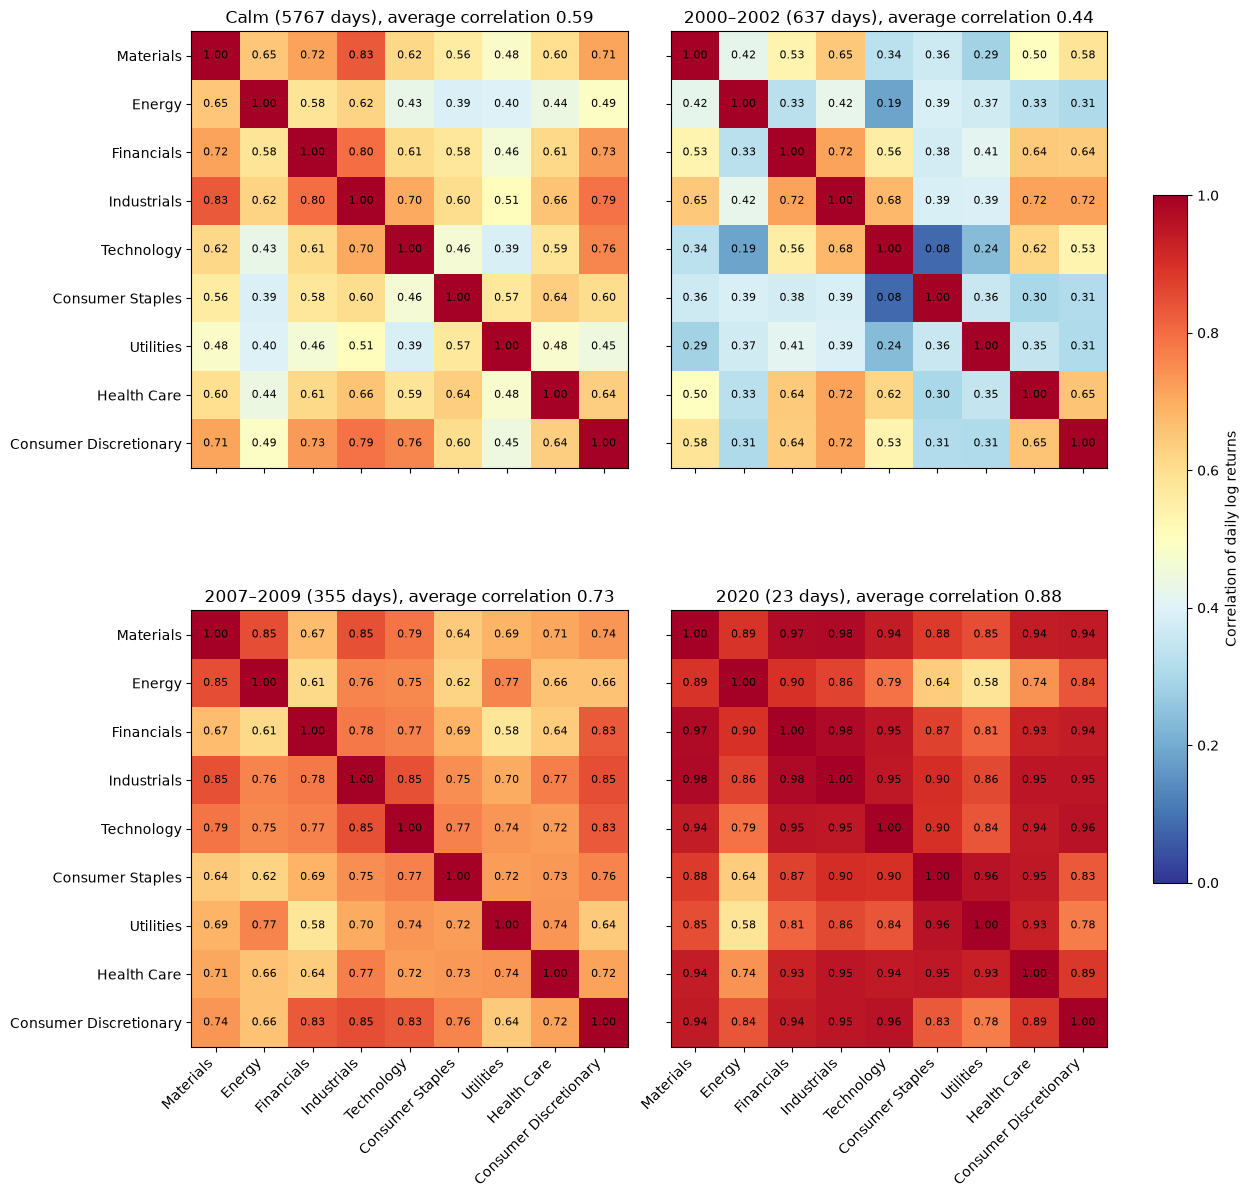

In [7]:
# --- run ---
masks = regime_masks(returns.index, crises)
mats = regime_matrices(returns["log"], masks)

summary = regime_summary(mats)
display(summary.style.format({"Days": "{:.0f}", "Avg sector vol (ann.)": "{:.1%}",
                              "Avg correlation": "{:.2f}", "Min correlation": "{:.2f}",
                              "Max correlation": "{:.2f}", "Min eigenvalue (corr)": "{:.3f}"}))

fig, axes = plot_corr_heatmaps(mats, regimes=("Calm", "2000–2002", "2007–2009", "2020"), ncols=2)
fig.savefig("assets/correlation_calm_vs_crisis.png", dpi=150, bbox_inches="tight")
plt.show()

| Regime | Days | Avg sector vol | Avg correlation | Min | Max | Min eigenvalue |
|:---|:---|:---|:---|:---|:---|:---|
| Calm | 5,767 | 18.8% | 0.59 | 0.39 | 0.83 | 0.141 |
| All crises | 1,210 | 34.9% | 0.62 | 0.42 | 0.80 | 0.135 |
| 2000–2002 | 637 | 28.4% | **0.44** | 0.08 | 0.72 | 0.185 |
| 2007–2009 | 355 | 41.1% | **0.73** | 0.58 | 0.85 | 0.106 |
| 2020 | 23 | 86.4% | **0.88** | 0.58 | 0.98 | 0.008 |
| 2022 | 195 | 26.0% | 0.62 | 0.23 | 0.91 | 0.069 |

Volatility always rises in crises, but correlations do not behave the same way in every crisis. Pooling all crises hides this: the 2000–2002 episode accounts for more than half of the crisis days and pulls the pooled average down to 0.62.

- **2000–2002, a sector bubble:** technology was almost uncorrelated with defensive sectors (0.08 with Consumer Staples, 0.19 with Energy). Money rotated out of technology into those sectors, and sector diversification worked.
- **2007–2009, a systemic crisis:** every sector fell together; even Utilities and Consumer Staples reached correlations of 0.6 to 0.77 with the rest.
- **2020, a global shock:** almost every correlation exceeds 0.9. Energy is the partial exception, because oil had its own crisis (the March 2020 price war).

All matrices are positive definite, hence also positive semidefinite. The 2020 matrix, estimated on 23 days with correlations up to 0.98, is close to singular (smallest eigenvalue 0.008).

## 4. How much of the crisis correlation is a volatility effect?

When the volatility of a common factor (here, the market) rises, correlations rise mechanically, even if the underlying relationship between sectors is unchanged. Forbes & Rigobon (2002) correct for this effect:

$$\rho^* = \frac{\rho}{\sqrt{1 + \delta\,(1 - \rho^2)}}, \qquad \delta = \frac{\sigma^2_{\text{SPY, crisis}}}{\sigma^2_{\text{SPY, calm}}} - 1$$

The correction is applied to every pair of sectors, with δ measured on the SPY. This assumes that the market is the channel through which the shock spreads.

In [8]:
def forbes_rigobon(corr, delta):
    """Forbes & Rigobon (2002) heteroskedasticity correction, pair by pair:
    rho* = rho / sqrt(1 + delta * (1 - rho^2)); the diagonal stays at 1."""
    rho = np.asarray(corr, dtype=float)
    adj = rho / np.sqrt(1 + delta * (1 - rho**2))
    np.fill_diagonal(adj, 1.0)
    return pd.DataFrame(adj, index=corr.index, columns=corr.columns)


def fr_correction(log_returns, masks, mats, crises, benchmark=BENCHMARK):
    """Delta from the benchmark variance (crisis vs calm), raw and corrected correlations."""
    var_calm = log_returns.loc[masks["Calm"], benchmark].var()
    rows, corrected = {}, {}
    for name in crises.index:
        delta = log_returns.loc[masks[name], benchmark].var() / var_calm - 1
        raw = mats[name]["corr"]
        adj = forbes_rigobon(raw, delta)
        corrected[name] = adj
        rows[name] = {
            "Days": mats[name]["n"],
            "Delta": delta,
            "Calm avg corr": mean_offdiag(mats["Calm"]["corr"]),
            "Raw avg corr": mean_offdiag(raw),
            "Corrected avg corr": mean_offdiag(adj),
            "Min eigenvalue (corrected)": np.linalg.eigvalsh(adj).min(),
            "Positive definite": is_positive_definite(adj),
        }
    return pd.DataFrame(rows).T, corrected


def plot_fr(table):
    """Average sector correlation per crisis: raw vs Forbes-Rigobon corrected, calm as reference."""
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(x - 0.2, table["Raw avg corr"], width=0.4, color="firebrick", label="Raw (crisis)")
    ax.bar(x + 0.2, table["Corrected avg corr"], width=0.4, color="steelblue",
           label="Corrected (Forbes & Rigobon)")
    ax.axhline(table["Calm avg corr"].iloc[0], color="black", linestyle="--", linewidth=1,
               label=f"Calm ({table['Calm avg corr'].iloc[0]:.2f})")
    for i, (raw, adj) in enumerate(zip(table["Raw avg corr"], table["Corrected avg corr"])):
        ax.text(i - 0.2, raw + 0.01, f"{raw:.2f}", ha="center", va="bottom", fontsize=9)
        ax.text(i + 0.2, adj + 0.01, f"{adj:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, [f"{n}\n(δ = {d:.1f})" for n, d in zip(table.index, table["Delta"])])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Average pairwise correlation (9 sectors)")
    ax.set_title("Crisis correlations before and after the volatility correction")
    ax.legend(frameon=False, loc="upper left")
    ax.grid(True, axis="y", alpha=0.3)
    fig.tight_layout()
    return fig, ax

,Days,Delta,Calm avg corr,Raw avg corr,Corrected avg corr,Min eigenvalue (corrected),Positive definite
2000–2002,637,1.25,0.59,0.44,0.32,0.351,True
2007–2009,355,4.85,0.59,0.73,0.41,0.384,True
2020,23,23.40,0.59,0.88,0.41,0.284,True
2022,195,1.38,0.59,0.62,0.48,0.162,True


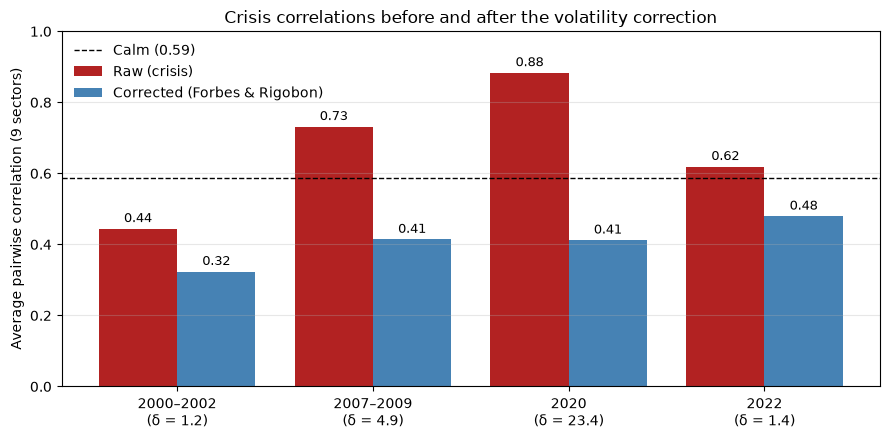

In [9]:
# --- run ---
fr_table, fr_corr = fr_correction(returns["log"], masks, mats, crises)
display(fr_table.style.format({"Days": "{:.0f}", "Delta": "{:.2f}", "Calm avg corr": "{:.2f}",
                               "Raw avg corr": "{:.2f}", "Corrected avg corr": "{:.2f}",
                               "Min eigenvalue (corrected)": "{:.3f}"}))

fig, ax = plot_fr(fr_table)
fig.savefig("assets/forbes_rigobon_correction.png", dpi=150, bbox_inches="tight")
plt.show()

| Crisis | δ | Raw | Corrected |
|:---|:---|:---|:---|
| 2000–2002 | 1.25 | 0.44 | 0.32 |
| 2007–2009 | 4.85 | 0.73 | 0.41 |
| 2020 | 23.40 | 0.88 | 0.41 |
| 2022 | 1.38 | 0.62 | 0.48 |

After the correction, every crisis correlation falls **below** the calm level of 0.59. This is the classic result of Forbes & Rigobon: "no contagion, only interdependence". The links between sectors do not strengthen in crises; the volatility of the common factor does.

Two caveats matter. First, the correction probably overshoots: if it were exact, corrected correlations should return to *around* 0.59, not well below it. The formula assumes that only the market variance rises, while sector-specific variance also rises in crises (banks in 2008, energy in 2020), a pitfall documented by Corsetti, Pericoli & Sbracia (2005). With δ = 23.4 for 2020, the result depends almost entirely on this assumption, so the corrected values are best read as a lower bound. Second, the correction answers a question about structure. An investor still bears the **raw** correlation: in 2020, the nine sectors fell together with an average correlation of 0.88. The Monte Carlo in section 7 therefore uses raw correlations.

All corrected matrices remain positive definite; their smallest eigenvalues even increase, because the correction shrinks the off-diagonal entries.

## 5. Absorption ratio

A symmetric matrix can be diagonalized as R = BΛBᵀ, where Λ holds the eigenvalues and B the orthogonal eigenvectors. The absorption ratio (Kritzman, Li, Page & Rigobon, 2011) is the share of total variance absorbed by the n largest eigenvalues:

$$AR = \frac{\sum_{i=1}^{n} \lambda_i}{\sum_{i=1}^{N} \lambda_i}$$

with n = 2, about one fifth of the nine sectors. A high value means that sectors move as a block. Unlike Kritzman et al., who use the covariance matrix, it is computed here on the **correlation** matrix, so that the most volatile sectors do not dominate the eigenvalues. Its minimum is 2/9 ≈ 0.22, for independent sectors. It is computed by regime and on rolling 500-day and 63-day windows that use past data only.

In [10]:
def absorption_ratio(corr, n=N_FACTORS):
    """Share of total variance absorbed by the n largest eigenvalues of a correlation matrix."""
    eig = np.sort(np.linalg.eigvalsh(corr))[::-1]       # descending
    return eig[:n].sum() / eig.sum()


def ar_by_regime(mats, n=N_FACTORS):
    """Absorption ratio and share of the first eigenvalue, per regime."""
    rows = {}
    for name, m in mats.items():
        eig = np.sort(np.linalg.eigvalsh(m["corr"]))[::-1]
        rows[name] = {"Days": m["n"],
                      "First eigenvalue": eig[0],
                      "Share of 1st eigenvalue": eig[0] / eig.sum(),
                      f"Absorption ratio (n={n})": eig[:n].sum() / eig.sum()}
    return pd.DataFrame(rows).T


def rolling_ar(log_returns, window, n=N_FACTORS, assets=SECTORS):
    """Absorption ratio on a trailing window of `window` days, recomputed every day."""
    x = log_returns[assets].to_numpy()
    values = [absorption_ratio(np.corrcoef(x[t - window:t].T), n)
              for t in range(window, len(x) + 1)]
    return pd.Series(values, index=log_returns.index[window - 1:], name=f"AR {window}d")


def plot_rolling_ar(ar_series, crises, n=N_FACTORS, n_assets=len(SECTORS)):
    """Rolling absorption ratios with the crisis windows shaded."""
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for s, color in zip(ar_series, ["black", "darkorange"]):
        ax.plot(s.index, s, color=color, linewidth=1, label=s.name)
    for name, row in crises.iterrows():
        ax.axvspan(pd.Timestamp(row["Peak"]), pd.Timestamp(row["Trough"]), color="red", alpha=0.12)
        ax.text(pd.Timestamp(row["Peak"]), 1.0, name, fontsize=9, va="bottom")
    ax.axhline(n / n_assets, color="grey", linestyle=":", linewidth=1,
               label=f"No common factor ({n}/{n_assets} = {n / n_assets:.2f})")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(f"Absorption ratio (top {n} eigenvalues)")
    ax.set_title("How much of sector risk is driven by a few common factors?")
    ax.legend(frameon=False, loc="lower left")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax

,Days,First eigenvalue,Share of 1st eigenvalue,Absorption ratio (n=2)
Calm,5767,5.76,64.0%,72.9%
All crises,1210,5.96,66.3%,74.9%
2000–2002,637,4.69,52.2%,65.7%
2007–2009,355,6.86,76.3%,82.9%
2020,23,8.09,89.8%,96.5%
2022,195,6.12,68.0%,78.1%


AR 500d: min 56.8% (2000-12-29), max 90.5% (2012-04-18)
AR 63d: min 39.9% (2000-09-08), max 96.2% (2020-03-17)


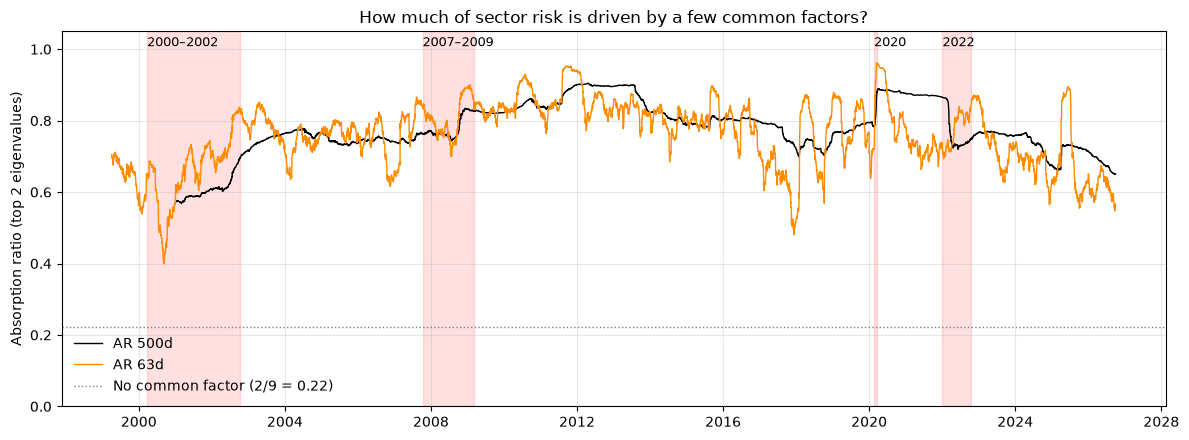

In [11]:
# --- run ---
ar_table = ar_by_regime(mats)
display(ar_table.style.format({"Days": "{:.0f}", "First eigenvalue": "{:.2f}",
                               "Share of 1st eigenvalue": "{:.1%}",
                               f"Absorption ratio (n={N_FACTORS})": "{:.1%}"}))

ar_rolling = [rolling_ar(returns["log"], w) for w in AR_WINDOWS]
for s in ar_rolling:
    print(f"{s.name}: min {s.min():.1%} ({s.idxmin().date()}), max {s.max():.1%} ({s.idxmax().date()})")

fig, ax = plot_rolling_ar(ar_rolling, crises)
fig.savefig("assets/absorption_ratio.png", dpi=150, bbox_inches="tight")
plt.show()

| Regime | First eigenvalue | Share of 1st eigenvalue | Absorption ratio (n = 2) |
|:---|:---|:---|:---|
| Calm | 5.76 | 64.0% | 72.9% |
| 2000–2002 | 4.69 | 52.2% | 65.7% |
| 2007–2009 | 6.86 | 76.3% | 82.9% |
| 2020 | 8.09 | **89.8%** | **96.5%** |
| 2022 | 6.12 | 68.0% | 78.1% |

During the Covid crash, a single factor explains 90% of the variance of the nine sectors. The rolling ratios add three points:

- **The 63-day ratio reacts quickly.** It peaks at 96.2% on 17 March 2020 and bottoms at 39.9% in September 2000, during the dot-com rotation. It also spikes in episodes the 20% rule does not classify as crises, such as 2018 and April 2025.
- **The 500-day ratio peaks outside any crisis**, at 90.5% in April 2012. In 2010–2013 (euro-area debt crisis, US downgrade), markets were in a "risk-on / risk-off" regime and all sectors moved with macro news. The absorption ratio measures fragility, not crises; testing it as an early-warning signal would require an out-of-sample study.
- **The step changes in the 500-day ratio are an artefact.** The drop in early 2022 is not a market event: the March 2020 days leave the window about 500 trading days later. Kritzman et al. avoid this with exponential weighting.

## 6. Stress matrices that are not positive definite

Cholesky factorization S = LLᵀ, the basis of the Monte Carlo in section 7, requires a **strictly** positive definite matrix. Two realistic ways to build a stress matrix can break this property:

1. **Worst case, pair by pair.** A common stress-testing practice takes, for each pair of sectors, the highest correlation observed in any crisis. Each entry then comes from a different period, and nothing guarantees that the resulting matrix is still a valid correlation matrix.
2. **Inconsistent expert judgment.** Technology set to move with both Energy and Consumer Staples (0.95), while Energy and Consumer Staples are set as unrelated (0.00). This is impossible: the 3×3 block has determinant 1 − 2 × 0.95² < 0.

Two repairs are compared. **Eigenvalue clipping** (Rebonato & Jäckel, 2000) floors the eigenvalues at 10⁻⁸, rebuilds the matrix and rescales its diagonal to 1 with D^(−1/2) A D^(−1/2). The floor is 10⁻⁸ rather than 0, because a zero eigenvalue would leave the matrix only semidefinite and Cholesky would still fail. **Higham's (2002) nearest correlation matrix** alternates projections between the two constraints, eigenvalues above the floor and a unit diagonal, with Dykstra's correction, and converges to the closest valid matrix in Frobenius norm.

In [12]:
def worst_case_corr(mats, crises):
    """Stress matrix: for each pair, the highest correlation observed in any crisis."""
    stack = np.stack([mats[name]["corr"].to_numpy() for name in crises.index])
    ref = mats[crises.index[0]]["corr"]
    return pd.DataFrame(stack.max(axis=0), index=ref.index, columns=ref.columns)


def expert_override(corr, overrides=EXPERT_OVERRIDES):
    """Copy of `corr` with some pairs set by hand (both (i, j) and (j, i))."""
    out = corr.copy()
    for (a, b), v in overrides.items():
        out.loc[a, b] = out.loc[b, a] = v
    return out


def cholesky_ok(matrix):
    """True if numpy's Cholesky factorization succeeds."""
    try:
        np.linalg.cholesky(matrix)
        return True
    except np.linalg.LinAlgError:
        return False


def clip_repair(corr, floor=EIG_FLOOR):
    """Eigenvalue clipping (Rebonato & Jaeckel, 2000): floor the eigenvalues, rebuild,
    then rescale to a unit diagonal with D^-1/2 A D^-1/2 (a congruence: stays PD)."""
    eigval, eigvec = np.linalg.eigh(corr)
    a = eigvec @ np.diag(np.maximum(eigval, floor)) @ eigvec.T
    d = 1 / np.sqrt(np.diag(a))
    a = a * np.outer(d, d)
    a = (a + a.T) / 2                      # remove rounding asymmetry
    return pd.DataFrame(a, index=corr.index, columns=corr.columns)


def higham_repair(corr, floor=EIG_FLOOR, max_iter=500, tol=1e-10):
    """Nearest correlation matrix (Higham, 2002): alternating projections with Dykstra's
    correction, between {eigenvalues >= floor} and {unit diagonal}."""
    a = np.asarray(corr, dtype=float)
    y, ds = a.copy(), np.zeros_like(a)
    for _ in range(max_iter):
        r = y - ds
        eigval, eigvec = np.linalg.eigh(r)
        x = eigvec @ np.diag(np.maximum(eigval, floor)) @ eigvec.T   # projection 1: PSD (floored)
        ds = x - r
        y_new = x.copy()
        np.fill_diagonal(y_new, 1.0)                                  # projection 2: unit diagonal
        if np.linalg.norm(y_new - y, "fro") < tol:
            y = y_new
            break
        y = y_new
    y = (y + y.T) / 2
    return pd.DataFrame(y, index=corr.index, columns=corr.columns)


def repair_report(original, repaired):
    """How far each repaired matrix is from the original, and whether Cholesky now works."""
    rows = {}
    for name, m in repaired.items():
        diff = (m - original).to_numpy()
        rows[name] = {"Min eigenvalue": np.linalg.eigvalsh(m).min(),
                      "Frobenius distance": np.linalg.norm(diff, "fro"),
                      "Largest change": np.abs(diff).max(),
                      "Unit diagonal": np.allclose(np.diag(m), 1),
                      "Cholesky OK": cholesky_ok(m)}
    return pd.DataFrame(rows).T


def largest_changes(original, repaired, k=5):
    """The k pairs whose correlation moved the most during the repair."""
    diff = repaired - original
    pairs = [(a, b) for i, a in enumerate(diff.index) for b in diff.columns[i + 1:]]
    rows = [{"Pair": f"{a} / {b}", "Original": original.loc[a, b],
             "Repaired": repaired.loc[a, b], "Change": diff.loc[a, b]} for a, b in pairs]
    return (pd.DataFrame(rows).set_index("Pair")
            .sort_values("Change", key=abs, ascending=False).head(k))

In [13]:
# --- run ---
# 1. worst case, pair by pair
worst = worst_case_corr(mats, crises)
print(f"Worst-case matrix: min eigenvalue {np.linalg.eigvalsh(worst).min():.4f}, "
      f"positive definite: {is_positive_definite(worst)}, Cholesky OK: {cholesky_ok(worst)}")

# 2. inconsistent expert judgment on top of the calm matrix
stress = expert_override(mats["Calm"]["corr"])
print(f"Expert stress matrix: min eigenvalue {np.linalg.eigvalsh(stress).min():.4f}, "
      f"positive definite: {is_positive_definite(stress)}, Cholesky OK: {cholesky_ok(stress)}")

try:
    np.linalg.cholesky(stress)
except np.linalg.LinAlgError as e:
    print(f"np.linalg.cholesky(stress) -> LinAlgError: {e}")

# 3. repair and compare
repaired = {"Clipping": clip_repair(stress), "Higham": higham_repair(stress)}
display(repair_report(stress, repaired).style.format(
    {"Min eigenvalue": "{:.2e}", "Frobenius distance": "{:.3f}", "Largest change": "{:.3f}"}))

for name, m in repaired.items():
    print(f"\n{name}: largest corrections")
    display(largest_changes(stress, m).style.format("{:.2f}"))

# 4. repair the realistic case too: the worst-case matrix
worst_repaired = {"Clipping": clip_repair(worst), "Higham": higham_repair(worst)}
display(repair_report(worst, worst_repaired).style.format(
    {"Min eigenvalue": "{:.2e}", "Frobenius distance": "{:.3f}", "Largest change": "{:.3f}"}))
display(largest_changes(worst, worst_repaired["Higham"]).style.format("{:.2f}"))

Worst-case matrix: min eigenvalue -0.0448, positive definite: False, Cholesky OK: False
Expert stress matrix: min eigenvalue -0.4152, positive definite: False, Cholesky OK: False
np.linalg.cholesky(stress) -> LinAlgError: Matrix is not positive definite


,Min eigenvalue,Frobenius distance,Largest change,Unit diagonal,Cholesky OK
Clipping,8.87e-09,0.559,0.236,True,True
Higham,9.97e-09,0.501,0.208,True,True



Clipping: largest corrections


,Original,Repaired,Change
Pair,,,
Technology / Consumer Staples,0.95,0.71,-0.24
Energy / Technology,0.95,0.72,-0.23
Energy / Consumer Staples,0.00,0.11,0.11
Technology / Consumer Discretionary,0.76,0.68,-0.08
Consumer Staples / Utilities,0.57,0.51,-0.06



Higham: largest corrections


,Original,Repaired,Change
Pair,,,
Technology / Consumer Staples,0.95,0.74,-0.21
Energy / Technology,0.95,0.75,-0.20
Energy / Consumer Staples,0.00,0.17,0.17
Technology / Utilities,0.39,0.43,0.05
Consumer Staples / Utilities,0.57,0.53,-0.04


,Min eigenvalue,Frobenius distance,Largest change,Unit diagonal,Cholesky OK
Clipping,9.91e-09,0.064,0.022,True,True
Higham,9.99e-09,0.050,0.015,True,True


,Original,Repaired,Change
Pair,,,
Consumer Staples / Utilities,0.96,0.94,-0.02
Energy / Consumer Staples,0.64,0.65,0.01
Energy / Utilities,0.77,0.75,-0.01
Financials / Consumer Staples,0.87,0.86,-0.01
Financials / Utilities,0.81,0.82,0.01


Both stress matrices fail Cholesky: the worst-case matrix has a smallest eigenvalue of −0.0448, the expert matrix −0.4152.

| Repair | Matrix | Frobenius distance | Largest change | Cholesky |
|:---|:---|:---|:---|:---|
| Clipping | Expert | 0.559 | 0.236 | OK |
| Higham | Expert | **0.501** | **0.208** | OK |
| Clipping | Worst case | 0.064 | 0.022 | OK |
| Higham | Worst case | **0.050** | **0.015** | OK |

- **The worst-case matrix is the realistic case.** Each crisis matrix is valid on its own, but mixing entries from different crises is not. The most corrected pair is Consumer Staples / Utilities, whose 0.96 comes from the 23 days of 2020: one noisy estimate from a small sample is enough to make the whole matrix unusable for Cholesky.
- **Higham stays closer to the original**, about 10% less distance than clipping in both cases, as theory requires, and spreads the correction more evenly across pairs.
- **The expert's three inconsistent pairs are brought back to compatible values:** with Higham, 0.74 for Technology / Consumer Staples, 0.75 for Energy / Technology and 0.17 for Energy / Consumer Staples. If Technology follows both Energy and Consumer Staples at 0.75, those two must themselves be somewhat correlated.

A negative eigenvalue does not mean the matrix is badly wrong: here, a largest change of 0.015 makes it valid. But it must be repaired before any simulation.

## 7. Monte Carlo simulation

Correlated returns are simulated with the Cholesky factor L of each correlation matrix, then scaled by each sector's volatility and shifted by its mean:

$$X = \mu + \text{diag}(\sigma)\, L\, Z, \qquad Z \sim \mathcal{N}(0, I)$$

The portfolio holds the nine sectors in equal weights, rebalanced daily. Correlations, volatilities and means are all estimated on **simple** returns, since a portfolio return is the weighted average of simple returns. Mean returns are the full-sample sector means in **every** scenario (11.1% per year for the portfolio), so that only risk changes between scenarios:

| Scenario | Correlations | Volatilities |
|:---|:---|:---|
| 1. Calm | Calm | Calm |
| 2. Crisis correlations only | 2007–2009 | Calm |
| 3. Crisis volatilities only | Calm | 2007–2009 |
| 4. Crisis correlations + volatilities | 2007–2009 | 2007–2009 |
| 5. Worst-case stress | Worst-case matrix repaired by Higham | 2007–2009 |

2007–2009 is the reference crisis: systemic, and long enough (355 days) for a stable estimate. Scenarios 2 and 3 separate the two effects. Adding correlations first and volatilities second (1 → 2 → 4), or the reverse (1 → 3 → 4), attributes the interaction between them differently, so both orders are computed and averaged (a Shapley decomposition). The worst-case matrix comes from the log-return matrices of section 6; the run cell prints the largest gap between simple and log correlations to check that this does not matter.

Each scenario uses 10,000 simulated one-year paths with a fixed seed. The ratio of simulated to analytic portfolio volatility, √(wᵀΣw), checks the simulation. The run cell also prints the upper bound of the correlation effect: with every correlation equal to 1, portfolio volatility equals the average sector volatility.

In [14]:
def scenario_inputs(returns, masks, stress_corr, ref=REF_CRISIS, assets=SECTORS):
    """Correlation matrix and daily volatilities of each scenario; one common mean vector.
    Correlations, volatilities and means all come from SIMPLE returns. The stress matrix
    comes from the log-return matrices of section 3 (see the check printed in the run cell)."""
    simple = returns["simple"][assets]
    mu = simple.mean()                                   # same mean in every scenario
    calm, crisis = simple.loc[masks["Calm"]], simple.loc[masks[ref]]
    corr_calm, corr_crisis = calm.corr(), crisis.corr()
    vol_calm, vol_crisis = calm.std(), crisis.std()
    scenarios = {
        "1. Calm": (corr_calm, vol_calm),
        "2. Crisis correlations only": (corr_crisis, vol_calm),
        "3. Crisis volatilities only": (corr_calm, vol_crisis),
        "4. Crisis correlations + volatilities": (corr_crisis, vol_crisis),
        "5. Worst-case stress (Higham)": (stress_corr, vol_crisis),
    }
    return scenarios, mu


def decompose(mc_table, column):
    """Correlation vs volatility effect, in both orders, and their average (Shapley)."""
    p = mc_table[column]
    calm, corr = p["1. Calm"], p["2. Crisis correlations only"]
    vol, both = p["3. Crisis volatilities only"], p["4. Crisis correlations + volatilities"]
    out = pd.DataFrame({
        "Correlations first": {"Correlation effect": corr - calm, "Volatility effect": both - corr},
        "Volatilities first": {"Correlation effect": both - vol, "Volatility effect": vol - calm},
    }).T
    out.loc["Average (Shapley)"] = out.mean()
    return out


def simulate_portfolio(mu, vol, corr, n_paths, n_days, weights, rng, chunk=1_000):
    """SIMULATED daily portfolio returns: X = mu + diag(sigma) L Z for each sector, then w'X."""
    L = np.linalg.cholesky(corr)              # fails if corr is not positive definite
    out = np.empty((n_paths, n_days))
    for start in range(0, n_paths, chunk):
        m = min(chunk, n_paths - start)
        z = rng.standard_normal((m, n_days, len(mu)))            # independent N(0, 1)
        x = mu.to_numpy() + (z @ L.T) * vol.to_numpy()           # correlated sector returns
        out[start:start + m] = x @ weights                       # portfolio return
    return out


def monte_carlo(scenarios, mu, weights=WEIGHTS, n_paths=N_PATHS, horizons=HORIZONS,
                losses=LOSS_LEVELS, periods=TRADING_DAYS, seed=SEED):
    """Loss probabilities per horizon, plus analytic risk figures, for each scenario."""
    rng = np.random.default_rng(seed)
    n_days = max(horizons.values())
    rows, one_year = {}, {}
    for name, (corr, vol) in scenarios.items():
        cov = corr_to_cov(corr.to_numpy(), vol.to_numpy())
        port_vol = np.sqrt(weights @ cov @ weights)              # analytic daily vol
        rp = simulate_portfolio(mu, vol, corr, n_paths, n_days, weights, rng)
        wealth = np.cumprod(1 + rp, axis=1)
        row = {"Sector vol (avg, ann.)": vol.mean() * np.sqrt(periods),
               "Portfolio vol (ann.)": port_vol * np.sqrt(periods),
               "Diversification ratio": (weights @ vol.to_numpy()) / port_vol,
               "Simulated vol / analytic": rp.std() / port_vol}
        for label, h in horizons.items():
            r = wealth[:, h - 1] - 1
            for loss in losses:
                row[f"P(loss > {loss:.0%}) {label}"] = (r < -loss).mean()
        rows[name] = row
        one_year[name] = wealth[:, -1] - 1
    return pd.DataFrame(rows).T, pd.DataFrame(one_year)


def plot_one_year(one_year, loss=0.20):
    """Distribution of SIMULATED one-year portfolio returns, per scenario."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bins = np.linspace(-0.9, 2.0, 170)
    for (name, r), color in zip(one_year.items(),
                                ["grey", "steelblue", "darkorange", "firebrick", "black"]):
        ax.hist(r, bins=bins, histtype="step", linewidth=1.5, color=color,
                label=f"{name}: P(loss > {loss:.0%}) = {(r < -loss).mean():.1%}")
    ax.axvline(-loss, color="red", linestyle="--", linewidth=1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("One-year return of the equal-weight sector portfolio (simulated)")
    ax.set_ylabel("Number of simulated paths")
    ax.set_title(f"Monte Carlo, {len(one_year):,} paths per scenario (Gaussian, same mean everywhere)")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax

Calm: largest gap between simple and log correlations = 0.0030
2007–2009: largest gap between simple and log correlations = 0.0091


,"Sector vol (avg, ann.)",Portfolio vol (ann.),Diversification ratio,Simulated vol / analytic
1. Calm,18.8%,15.0%,1.25,0.999
2. Crisis correlations only,18.8%,16.5%,1.14,1.000
3. Crisis volatilities only,41.1%,33.0%,1.24,1.000
4. Crisis correlations + volatilities,41.1%,35.8%,1.15,1.000
5. Worst-case stress (Higham),41.1%,39.1%,1.05,1.000


,P(loss > 10%) 1 day,P(loss > 20%) 1 day,P(loss > 10%) 1 month,P(loss > 20%) 1 month,P(loss > 10%) 1 year,P(loss > 20%) 1 year
1. Calm,0.00%,0.00%,0.47%,0.00%,9.07%,1.75%
2. Crisis correlations only,0.00%,0.00%,0.78%,0.00%,11.78%,2.89%
3. Crisis volatilities only,0.00%,0.00%,12.26%,0.89%,31.14%,20.04%
4. Crisis correlations + volatilities,0.00%,0.00%,14.56%,1.57%,33.16%,22.06%
5. Worst-case stress (Higham),0.00%,0.00%,16.83%,2.27%,36.27%,26.12%


Mean daily portfolio return used in every scenario: 0.0417% (11.1% per year)

Decomposition of Portfolio vol (ann.):


,Correlation effect,Volatility effect
Correlations first,+1.4%,+19.4%
Volatilities first,+2.8%,+18.0%
Average (Shapley),+2.1%,+18.7%



Decomposition of P(loss > 20%) 1 year:


,Correlation effect,Volatility effect
Correlations first,+1.14%,+19.17%
Volatilities first,+2.02%,+18.29%
Average (Shapley),+1.58%,+18.73%



Calm portfolio vol 15.0%; if every correlation were 1: 18.8% (x1.25 at most)


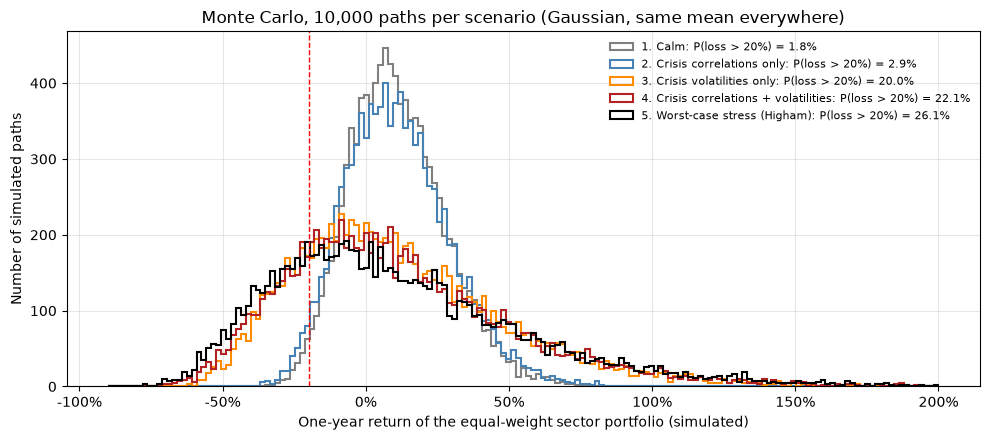

In [15]:
# --- run ---
scenarios, mu = scenario_inputs(returns, masks, worst_repaired["Higham"])

# check: simple vs log correlations (the stress matrix uses log returns)
for name in ("Calm", REF_CRISIS):
    simple_corr = returns["simple"].loc[masks[name], SECTORS].corr()
    gap = (simple_corr - mats[name]["corr"]).abs().to_numpy().max()
    print(f"{name}: largest gap between simple and log correlations = {gap:.4f}")

mc_table, one_year = monte_carlo(scenarios, mu)

risk_cols = ["Sector vol (avg, ann.)", "Portfolio vol (ann.)", "Diversification ratio",
             "Simulated vol / analytic"]
display(mc_table[risk_cols].style.format({"Sector vol (avg, ann.)": "{:.1%}",
                                          "Portfolio vol (ann.)": "{:.1%}",
                                          "Diversification ratio": "{:.2f}",
                                          "Simulated vol / analytic": "{:.3f}"}))
display(mc_table.drop(columns=risk_cols).style.format("{:.2%}"))
print(f"Mean daily portfolio return used in every scenario: {WEIGHTS @ mu:.4%} "
      f"({(1 + WEIGHTS @ mu) ** TRADING_DAYS - 1:.1%} per year)")

# decomposition of the crisis effect, in both orders
for col, fmt in [("Portfolio vol (ann.)", "{:+.1%}"), ("P(loss > 20%) 1 year", "{:+.2%}")]:
    print(f"\nDecomposition of {col}:")
    display(decompose(mc_table, col).style.format(fmt))

# upper bound of the correlation effect: with every correlation at 1, portfolio vol = average sector vol
calm_row = mc_table.loc["1. Calm"]
print(f"\nCalm portfolio vol {calm_row['Portfolio vol (ann.)']:.1%}; if every correlation were 1: "
      f"{calm_row['Sector vol (avg, ann.)']:.1%} (x{calm_row['Diversification ratio']:.2f} at most)")

fig, ax = plot_one_year(one_year)
fig.savefig("assets/monte_carlo_one_year.png", dpi=150, bbox_inches="tight")
plt.show()

All figures below are **simulated**. Simulated volatilities match the analytic ones (ratio 0.999 to 1.000), and simple and log correlations differ by at most 0.003 in calm periods and 0.009 in 2007–2009, which is negligible for the worst-case matrix.

| Scenario | Avg sector vol | Portfolio vol | Diversification ratio | P(loss > 20%), 1 month | P(loss > 20%), 1 year |
|:---|:---|:---|:---|:---|:---|
| 1. Calm | 18.8% | 15.0% | 1.25 | 0.00% | 1.75% |
| 2. Crisis correlations only | 18.8% | 16.5% | 1.14 | 0.00% | 2.89% |
| 3. Crisis volatilities only | 41.1% | 33.0% | 1.24 | 0.89% | 20.04% |
| 4. Crisis correlations + volatilities | 41.1% | 35.8% | 1.15 | 1.57% | 22.06% |
| 5. Worst-case stress | 41.1% | 39.1% | **1.05** | 2.27% | **26.12%** |

Decomposition of the move from scenario 1 to scenario 4, in both orders:

| | Portfolio volatility: correlation effect | Portfolio volatility: volatility effect | P(loss > 20%, 1 year): correlation effect | P(loss > 20%, 1 year): volatility effect |
|:---|:---|:---|:---|:---|
| Correlations first | +1.4 pts | +19.4 pts | +1.14 pts | +19.17 pts |
| Volatilities first | +2.8 pts | +18.0 pts | +2.02 pts | +18.29 pts |
| **Average (Shapley)** | **+2.1 pts** | **+18.7 pts** | **+1.58 pts** | **+18.73 pts** |

- **Volatility dominates, whatever the order.** Of the 20.3-point rise in the probability of a one-year loss above 20%, crisis volatilities account for 18.7 points and crisis correlations for 1.6. The same split holds for portfolio volatility (+18.7 vs +2.1 points).
- **The correlation effect is capped.** With calm volatilities, portfolio volatility is 15.0%; even if every correlation were 1, it would only reach the average sector volatility, 18.8%: a factor of 1.25 at most, the calm diversification ratio. Crisis correlations already take it to 16.5%. Volatilities have no such cap: average sector volatility more than doubles, from 18.8% to 41.1%. Sector diversification had little to lose because it had little to give.
- **Diversification still erodes.** The diversification ratio falls from 1.25 (calm) to 1.14 with crisis correlations and to 1.05 under worst-case stress, where portfolio volatility is only 5% below the average sector volatility.
- **The Gaussian model misses extreme days.** It gives a 0.00% probability of losing more than 10% in one day in every scenario, although the SPY lost 10.9% on 16 March 2020. Daily returns have fat tails that a normal distribution cannot reproduce.
- **One-year returns are right-skewed in the crisis scenarios**, with a lower median for the same mean: compounding with high volatility creates a volatility drag of about σ²/2.

Scenarios 3 to 5 assume that crisis volatility lasts a full year. This is consistent with 2007–2009 (355 days), but it is a stress scenario, not a forecast.

## 8. Conclusion

Does sector diversification survive market crises? **It depends on the crisis, and mostly it does not protect against the market itself.** When a crisis is driven by one part of the economy, as in 2000–2002, sector correlations fall and diversification works. When the shock is systemic, as in 2007–2009 and 2020, correlations rise towards 0.7–0.9, the first eigenvalue absorbs up to 90% of sector variance, and the diversification ratio of an equal-weight portfolio falls from 1.25 to about 1.05 under stress.

Two results qualify this picture. Most of the rise in crisis correlations is a volatility effect: after the Forbes & Rigobon correction, crisis correlations are no higher than calm ones. And in the Monte Carlo, the loss of diversification matters much less than the volatility shock itself: of the rise in the probability of a one-year loss above 20%, from 1.8% to 22.1%, crisis volatilities account for 18.7 points and crisis correlations for 1.6. The reason is structural: with a calm diversification ratio of 1.25, sector diversification only ever reduced portfolio volatility by 20%, so rising correlations could raise it by at most 25%, while crisis volatilities more than double. There was little to lose because there was little to gain. The practical lesson is that a portfolio spread across sectors of one equity market remains exposed to that market's crashes; protection requires assets with different risk drivers, not just different sectors. On the technical side, stress-test correlation matrices must be checked for positive definiteness and repaired, preferably with the nearest correlation matrix, before they are used in a simulation.

## Limitations and extensions

- **Crisis selection.** Crises are defined by SPY declines, which selects days of falling markets and inflates correlations, the very bias the Forbes & Rigobon correction addresses. The 20% threshold is a convention: 2018 and 2025 came close and are treated as calm.
- **Small samples.** The 2020 crisis has 23 observations; its correlations are noisy and its matrix is close to singular.
- **Volatility correction.** Forbes & Rigobon assume a single common shock and constant sector-specific variance, and are known to overcorrect (Corsetti, Pericoli & Sbracia, 2005). The same SPY δ is applied to every pair.
- **Absorption ratio.** Equal-weighted windows create step changes when extreme days leave the window; the ratio is computed on correlations rather than covariances, and it is not tested as an early-warning signal.
- **Monte Carlo.** Returns are Gaussian and independent from day to day: no fat tails and no volatility clustering. A multivariate Student t distribution would be the natural extension. Crisis volatility is assumed to last a year, and the same positive mean is used in every scenario, which understates crisis losses by design. The worst-case matrix is built from log-return correlations while the other scenarios use simple returns; the two differ by at most 0.009.
- **Universe.** The nine sectors are all US large caps exposed to the same market factor; the result concerns sector diversification, not diversification across asset classes. Daily rebalancing ignores transaction costs.

## References

- Corsetti, G., Pericoli, M., & Sbracia, M. (2005). "Some contagion, some interdependence": More pitfalls in tests of financial contagion. *Journal of International Money and Finance*, 24(8), 1177–1199.
- Forbes, K. J., & Rigobon, R. (2002). No contagion, only interdependence: Measuring stock market comovements. *Journal of Finance*, 57(5), 2223–2261.
- Higham, N. J. (2002). Computing the nearest correlation matrix — a problem from finance. *IMA Journal of Numerical Analysis*, 22(3), 329–343.
- Kritzman, M., Li, Y., Page, S., & Rigobon, R. (2011). Principal components as a measure of systemic risk. *Journal of Portfolio Management*, 37(4), 112–126.
- Rebonato, R., & Jäckel, P. (2000). The most general methodology to create a valid correlation matrix for risk management and option pricing purposes. *Journal of Risk*, 2(2), 17–27.